# Figure 2c
Temperature and fixation location probability on the network representing a river, with $N=10$ habitat patches, at $r=2$. The initial mutant is at the mouth (green arrow). The arrow between the two tributaries is a directed edge.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))
edges = [tuple(e) for e in d['edges']]

In [2]:
RIVER = {
  0: (0.05, 1.0), 1: (0.2, 2.0), 2: (0.3, 3.0), 3: (-0.5, 3.8), 4: (-1.0, 4.6), 5: (-1.7, 5.2), 6: (-0.7, 5.5),
  7: (1.05, 3.85), 8: (0.75, 4.85), 9: (1.75, 4.65),
}
pos = {v: ((x - 0.02) * 0.44, (y - 3.25) * 0.44) for v, (x, y) in RIVER.items()}
R = 0.115

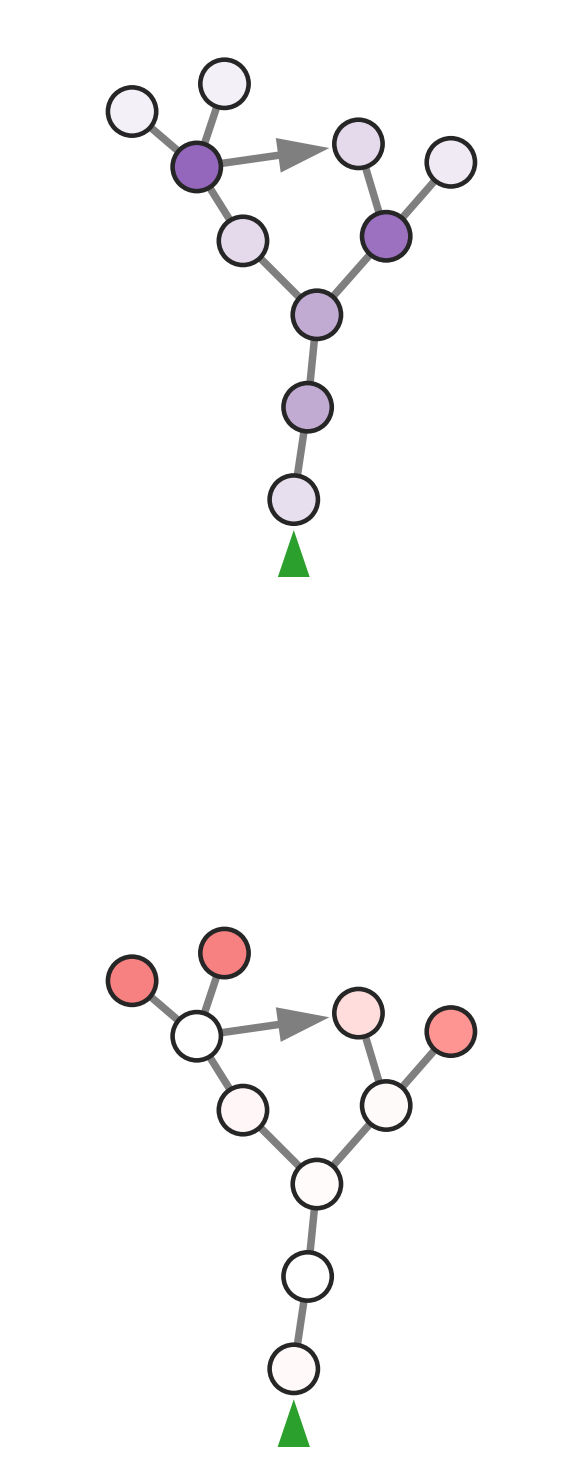

In [3]:
fig = plt.figure(figsize=(7.0, 4.75))
for y, vals, cmap, vmax in ((0.675, d['theta'], S.CM_TEMP, 2.5), (0.37, d['P_last'], S.CM_LAST, 0.5)):
  ax = fig.add_axes([0.5, y, 0.13, 0.29])
  fills = S.shade(cmap, dict(enumerate(np.array(vals))), 0, vmax)
  S.draw_graph(ax, pos, edges, fills, R=R, one_way=[tuple(d['channel'])], gap=0.025)
  x0, y0 = pos[d['origin']]
  S.arrow(ax, (x0, y0 - 0.36), (x0, y0 - R - 0.03), color=S.ORIGIN, lw=1.0, scale=7)
  ax.set_xlim(-1.3, 1.3)
  ax.set_ylim(-1.36, 1.3)
S.save_panel(fig, 'c')